# Premier League predictions: the full process

This notebook walks through how the model is built, step by step, with the reasoning behind each choice. Every number in it is calculated here from the data in this repo.

**The question:** before kickoff, can we predict whether a Premier League match ends in a home win (H), a draw (D) or an away win (A)?

**The plan**
1. Load the data and see what "normal" looks like
2. Set the benchmarks a model has to beat
3. The 2023 mistake: data leakage, and how to avoid it
4. Build features using only information available before kickoff
5. Train a model and test it on a season it has never seen
6. Repeat that test over 7 seasons to get a reliable number
7. Test your ideas: head-to-head, weather, team news (lineups) and seven more signals
8. What else was tried
9. When to trust the model: accuracy by confidence
10. This season and this weekend
11. Conclusions

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# chart style: one colour per role, quiet axes
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "lines.linewidth": 2, "font.size": 10})
pd.set_option("display.width", 140)

## 1. The data

`data/processed/matches.csv` combines two public sources:
- **Football-Data.co.uk** (via a GitHub mirror): every Premier League match since 2000/01, with score, shots and bookmaker odds.
- **openfootball**: results for the 2026/27 matches played after 31 August, which the first source doesn't have yet.

Built by `src/build_dataset.py`. Where the two sources overlap, the scores agree exactly.

In [2]:
matches = pd.read_csv(ROOT / "data/processed/matches.csv", parse_dates=["Date"])
print(f"{len(matches):,} matches from {matches.Date.min():%d %b %Y} to {matches.Date.max():%d %b %Y}")
matches[["Date", "Season", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "Result", "HS", "AS", "OddH", "OddD", "OddA"]].tail()

9,840 matches from 19 Aug 2000 to 20 Sep 2026


,Date,Season,HomeTeam,AwayTeam,FTHG,FTAG,Result,HS,AS,OddH,OddD,OddA
9835,2026-09-19,2026/27,Tottenham,Aston Villa,2.0,3.0,A,NaN,NaN,NaN,NaN,NaN
9836,2026-09-20,2026/27,Bournemouth,Liverpool,0.0,1.0,A,NaN,NaN,NaN,NaN,NaN
9837,2026-09-20,2026/27,Fulham,Man United,1.0,1.0,D,NaN,NaN,NaN,NaN,NaN
9838,2026-09-20,2026/27,Leeds,Crystal Palace,0.0,0.0,D,NaN,NaN,NaN,NaN,NaN
9839,2026-09-20,2026/27,Man City,Sunderland,5.0,3.0,H,NaN,NaN,NaN,NaN,NaN


**How often does each result happen?** This is the first thing to know, because a model has to do better than simply guessing the most common result.

In [3]:
print((matches.Result.value_counts(normalize=True) * 100).round(1).rename("% of matches"))

Result
H    45.6
A    29.6
D    24.8
Name: % of matches, dtype: float64


The home team wins about 45% of the time. So a "model" that always says *home win* is already right 45% of the time. That's the first benchmark.

The home advantage isn't constant, though. In 2020/21, when games were played without crowds because of COVID, it nearly disappeared:

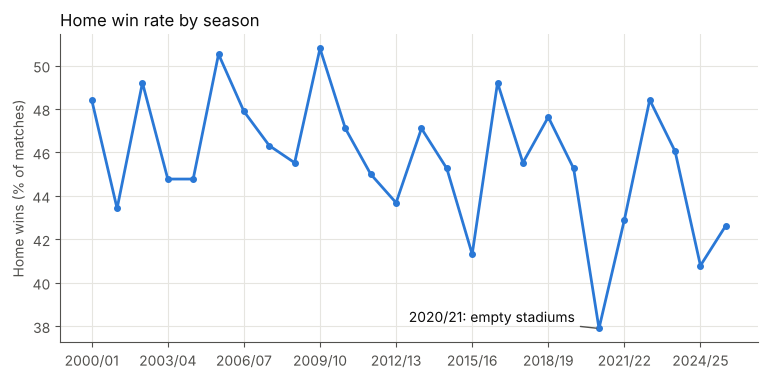

In [4]:
by_season = matches[matches.Season < "2026/27"].groupby("Season").Result.apply(lambda r: (r == "H").mean() * 100)
fig, ax = plt.subplots()
ax.plot(range(len(by_season)), by_season.values, color=BLUE, marker="o", markersize=4)
ax.set_xticks(range(0, len(by_season), 3), by_season.index[::3])
i = list(by_season.index).index("2020/21")
ax.annotate("2020/21: empty stadiums", (i, by_season.iloc[i]), xytext=(i - 7.5, by_season.iloc[i] + 0.3),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_ylabel("Home wins (% of matches)")
ax.set_title("Home win rate by season", loc="left", color=INK)
plt.show()

## 2. The benchmarks

Any model must be compared to:
1. **Always pick the home team**: about 43–45%.
2. **The bookmakers.** Their odds turn into probabilities: odds of 2.00 mean roughly a 50% chance. Picking the bookmakers' favourite is the strongest public benchmark there is, because bookmakers price in team news, injuries and huge amounts of data.

`src/features.py` removes the bookmaker margin, so the three probabilities add up to 100%.

In [5]:
from features import add_market_probs
mk = add_market_probs(matches.copy()).dropna(subset=["MktH"])
recent = mk[(mk.Season >= "2019/20") & (mk.Season <= "2025/26")]
fav = np.array(["H", "D", "A"])[recent[["MktH", "MktD", "MktA"]].to_numpy().argmax(1)]
print(f"Always home win, 2019/20-2025/26 : {(recent.Result == 'H').mean():.1%}")
print(f"Bookmakers' favourite, same seasons: {(fav == recent.Result).mean():.1%}")
print(f"How often the bookmakers' favourite is a draw: {(fav == 'D').mean():.1%}")

Always home win, 2019/20-2025/26 : 43.4%
Bookmakers' favourite, same seasons: 54.4%
How often the bookmakers' favourite is a draw: 0.0%


Two lessons from this:
- Even the bookmakers are right only about **54%** of the time. Football is random: one deflection changes the result.
- **The favourite is never a draw.** Draws make up about 25% of matches, but in the 2,660 matches from 2019/20 to 2025/26 the bookmakers never once made a draw the single *most likely* outcome. So any model scored on "pick the most likely result" will rarely predict a draw. That isn't a flaw; it's how the probabilities work.

## 3. The 2023 mistake: data leakage

**Leakage** means giving the model information it wouldn't have before kickoff. The 2023 notebook had two leaks:

1. **"Average goals in the last 5 matches" included the match being predicted.** If a team won 4–0, its "recent average" already contained those 4 goals, so the answer was hidden in the question.
2. **Accuracy was measured on matches the model had trained on.** A random forest memorises its training data, so it scores itself very well on it.

Here's the first leak on a real example. The fix is a single `.shift(1)`, which moves the window back one match so that it ends *before* the current game:

In [6]:
ars = matches[(matches.HomeTeam == "Arsenal") | (matches.AwayTeam == "Arsenal")].copy()
ars["Arsenal_goals"] = np.where(ars.HomeTeam == "Arsenal", ars.FTHG, ars.FTAG)
ars = ars[ars.Season == "2025/26"].head(8)[["Date", "HomeTeam", "AwayTeam", "Arsenal_goals"]]
ars["WRONG: avg incl. this match"] = ars.Arsenal_goals.rolling(5, min_periods=1).mean().round(2)
ars["RIGHT: avg of previous matches"] = ars.Arsenal_goals.shift(1).rolling(5, min_periods=1).mean().round(2)
ars

,Date,HomeTeam,AwayTeam,Arsenal_goals,WRONG: avg incl. this match,RIGHT: avg of previous matches
9417,2025-08-17,Man United,Arsenal,1.0,1.00,NaN
9421,2025-08-23,Arsenal,Leeds,5.0,3.00,1.00
9438,2025-08-31,Liverpool,Arsenal,0.0,2.00,3.00
9440,2025-09-13,Arsenal,Nott'm Forest,3.0,2.25,2.00
9457,2025-09-21,Arsenal,Man City,1.0,2.00,2.25
9468,2025-09-28,Newcastle,Arsenal,2.0,2.20,2.00
9471,2025-10-04,Arsenal,West Ham,2.0,1.60,2.20
9483,2025-10-18,Fulham,Arsenal,1.0,1.80,1.60


`src/leakage_demo.py` rebuilds the 2023 setup on the same seasons and shows what each leak was worth:

In [7]:
pd.read_csv(ROOT / "reports/leakage_demo.csv")

,rolling averages,scored on all rows incl. training,random 20% split,unseen next season 2022/23
0,include current match (2023 bug),0.925,0.623,0.652
1,previous matches only (fixed),0.890,0.450,0.496


How to read this table:
- **With the leak**, the model looks brilliant: 92% on its own training data, 65% on the next season.
- **Fixed**, it still scores 89% on its training data. That's memorisation, and it's why you must never score a model on data it has seen.
- The honest number is the last column: about **50%** on a season it has never seen.

The rule used from here on: **every feature for a match is calculated only from matches played before it, and every accuracy figure is measured on matches the model has never seen.**

## 4. Features: what the model gets to see

All built in `src/features.py`, using only past matches:

| Feature | What it means |
|---|---|
| **Elo rating** | A running strength score for each team. Win and you take points from your opponent; beat a strong team and you take more; win by a lot and you take more still. Ratings drift back toward the average between seasons, and promoted teams start below average. |
| **EloDiff** | Home Elo + home advantage − away Elo. The single most useful number. |
| **Form (last 5 and 10 matches)** | Goals scored, goals conceded and points per game, calculated *before* the match. |
| **Rest days** | Days since each team's previous match. |
| **Matches of history** | How much data exists on the team, so the model knows when a rating is still uncertain. |

**Each team's last results are already in here**, twice over: in the form features directly, and indirectly in Elo, which is a weighted summary of every previous result.

Elo settings, tuned on seasons before 2025/26: {'k': 20, 'home_adv': 50, 'carry': 0.9}


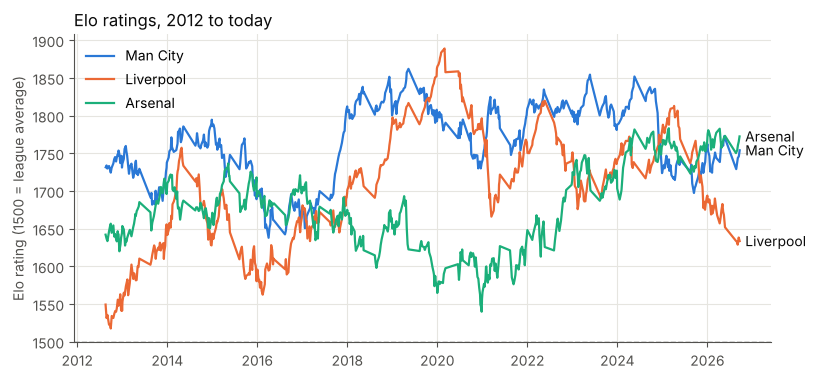

In [8]:
from features import build_features
elo_cfg = json.load(open(ROOT / "reports/metrics.json"))["elo"]
print("Elo settings, tuned on seasons before 2025/26:", elo_cfg)
df = build_features(matches, **elo_cfg)

fig, ax = plt.subplots()
for team, col in [("Man City", BLUE), ("Liverpool", ORANGE), ("Arsenal", AQUA)]:
    h = df[df.HomeTeam == team][["Date", "HomeElo"]].rename(columns={"HomeElo": "Elo"})
    a = df[df.AwayTeam == team][["Date", "AwayElo"]].rename(columns={"AwayElo": "Elo"})
    s = pd.concat([h, a]).sort_values("Date")
    s = s[s.Date >= "2012-07-01"]
    ax.plot(s.Date, s.Elo, color=col, label=team, linewidth=1.6)
    ax.annotate(team, (s.Date.iloc[-1], s.Elo.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color=INK, va="center")
ax.axhline(1500, color=MUTED, linewidth=1, linestyle="--")
ax.legend(loc="upper left", frameon=False)
ax.set_ylabel("Elo rating (1500 = league average)")
ax.set_title("Elo ratings, 2012 to today", loc="left", color=INK)
plt.show()

Here's everything the model sees for one match, all of it known before kickoff:

In [9]:
from evaluate import RESULTS_FEATS
example = df[(df.HomeTeam == "Liverpool") & (df.AwayTeam == "Man City")].iloc[-1]
print(example[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]].to_string(), "\n")
example[RESULTS_FEATS].round(2).to_frame("value")

Date        2026-02-08 00:00:00
HomeTeam              Liverpool
AwayTeam               Man City
FTHG                        1.0
FTAG                        2.0 



,value
EloDiff,6.05
HomeElo,1680.34
AwayElo,1724.29
D_GF_l5,0.6
D_GA_l5,0.2
D_Pts_l5,0.0
D_GF_l10,0.1
D_GA_l10,0.5
D_Pts_l10,-0.2
H_n_prev,965


## 5. Train on the past, test on an unseen season

**Time-based split:** train on every season up to 2024/25, then predict 2025/26. A random split would let the model learn from the future.

**The model** is a multinomial logistic regression. It turns the features into three probabilities that add up to 100%. It was chosen because it was as accurate as the more complex models (section 8) while being simple and hard to overfit. `C=0.1` adds regularisation, which stops the model leaning too hard on any one feature.

In [10]:
from evaluate import make_model, encode, CLASSES
usable = df.Season >= "2001/02"            # first season only warms up the ratings
train = usable & (df.Season < "2025/26")
test = df.Season == "2025/26"

model = make_model("logreg").fit(df.loc[train, RESULTS_FEATS], encode(df.loc[train, "Result"]))
proba = model.predict_proba(df.loc[test, RESULTS_FEATS])
pick = np.array(CLASSES)[proba.argmax(1)]
actual = df.loc[test, "Result"].to_numpy()

print(f"Trained on {train.sum():,} matches, tested on {test.sum()} matches of 2025/26")
print(f"Model accuracy       : {(pick == actual).mean():.1%}")
print(f"Always home win      : {(actual == 'H').mean():.1%}")
mk25 = df.loc[test, ["MktH", "MktD", "MktA"]].to_numpy()
print(f"Bookmakers' favourite: {(np.array(CLASSES)[mk25.argmax(1)] == actual).mean():.1%}")

Trained on 9,030 matches, tested on 380 matches of 2025/26
Model accuracy       : 48.4%
Always home win      : 42.6%
Bookmakers' favourite: 48.9%


**Where it goes right and wrong.** Rows are what happened; columns are what the model picked.

In [11]:
pd.crosstab(pd.Series(actual, name="Actual"), pd.Series(pick, name="Predicted")).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

Predicted,H,D,A
Actual,,,
H,132,0,30
D,67,0,37
A,62,0,52


As expected, the model almost never picks a draw. It gets most home wins right, about half the away wins, and every draw wrong. That's the same pattern as the bookmakers.

## 6. One season can be lucky or unlucky, so test seven

Accuracy swings by 5–8 points from season to season. So the same test is repeated for every season from 2019/20 to 2025/26, each time training only on earlier seasons. That's 2,660 matches in total.

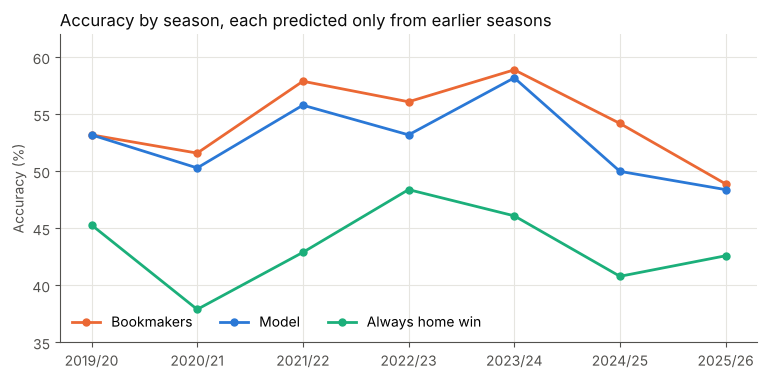

always_home_win    43.4
results_logreg     52.7
bookmakers         54.4
Name: average %, dtype: float64


In [12]:
bt = pd.read_csv(ROOT / "reports/backtest_by_season.csv")
fig, ax = plt.subplots()
x = range(len(bt))
for colname, label, col in [("bookmakers", "Bookmakers", ORANGE), ("results_logreg", "Model", BLUE),
                            ("always_home_win", "Always home win", AQUA)]:
    ax.plot(x, bt[colname] * 100, color=col, marker="o", markersize=5, label=label)
ax.set_xticks(list(x), bt.season)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(35, 62)
ax.legend(frameon=False, loc="lower left", ncol=3)
ax.set_title("Accuracy by season, each predicted only from earlier seasons", loc="left", color=INK)
plt.show()
print(bt[["season", "always_home_win", "results_logreg", "bookmakers"]].mean(numeric_only=True).mul(100).round(1).rename("average %"))

Over 2,660 matches the model averages about **53%**, against 43% for always picking home and 54% for the bookmakers. One standard error on 2,660 matches is about 1 point, so the model is genuinely close to the bookmakers but just below them.

## 7. Your ideas: head-to-head history and weather

### 7a. Head-to-head
For each match, `src/extra_signals.py` looks up the previous meetings between the same two clubs: the last 6 meetings within 6 years. It summarises them from the home team's point of view: average goal difference, points per game, the result at this same ground, and the draw rate.

Example: Liverpool vs Man City.

In [13]:
from extra_signals import add_h2h
h2h = add_h2h(df)
pair = h2h[((h2h.HomeTeam == "Liverpool") & (h2h.AwayTeam == "Man City")) | ((h2h.HomeTeam == "Man City") & (h2h.AwayTeam == "Liverpool"))]
pair[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "H2H_n", "H2H_gd", "H2H_pts", "H2H_venue_gd"]].tail(6).round(2)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,H2H_n,H2H_gd,H2H_pts,H2H_venue_gd
8773,2023-11-25,Man City,Liverpool,1.0,1.0,6.0,0.83,1.50,1.00
8925,2024-03-10,Liverpool,Man City,1.0,1.0,6.0,-0.83,1.00,-0.67
9157,2024-12-01,Liverpool,Man City,2.0,0.0,6.0,-0.33,1.17,0.33
9289,2025-02-23,Man City,Liverpool,0.0,2.0,6.0,0.00,1.00,1.00
9518,2025-11-09,Man City,Liverpool,3.0,0.0,6.0,-0.33,0.83,0.33
9659,2026-02-08,Liverpool,Man City,1.0,2.0,6.0,-0.33,1.33,1.00


**The test:** the v1 model with and without these features, on the same 7 seasons. Same matches, same model, and the only difference is the head-to-head columns. `src/test_extra_signals.py` produces these tables.

In [14]:
extra = json.load(open(ROOT / "reports/extra_signals.json"))
print(pd.read_csv(ROOT / "reports/h2h_backtest.csv").round(3).to_string(index=False))
h = extra["head_to_head"]
print(f"\nAccuracy change: {h['acc_change_pts']:+.2f} points (standard error {h['acc_change_se_pts']:.2f})")
print(f"RPS change     : {h['rps_change']:+.4f} (lower is better; standard error {h['rps_change_se']:.4f})")

 season    v1  v1 + head-to-head
2019/20 0.532              0.526
2020/21 0.503              0.508
2021/22 0.558              0.560
2022/23 0.532              0.537
2023/24 0.582              0.582
2024/25 0.500              0.500
2025/26 0.484              0.476

Accuracy change: +0.00 points (standard error 0.21)
RPS change     : +0.0004 (lower is better; standard error 0.0002)


**Result: head-to-head adds nothing.** Accuracy is unchanged over 2,660 matches, and the probabilities got very slightly worse.

Why it doesn't help, even though it sounds like it should:
- **Elo and form already contain it.** If Man City usually beat Burnley, that's mostly because Man City are much stronger, and Elo already says so. Head-to-head adds no new information.
- **Tiny samples.** Six meetings over six years cover different squads and managers. That's mostly noise, and a model that leans on noise gets worse.
- The "bogey team" effect people talk about is mostly memory bias: the surprising results are the ones we remember.

### 7b. Weather
The 2023 project collected daily weather for each Premier League city from August 2017 to April 2023. I matched each match to the weather in the home team's city that day.

First, does weather change how matches end at all?

In [15]:
pd.read_csv(ROOT / "reports/weather_descriptive.csv")

,conditions,matches,home win %,draw %,goals per match
0,all weather-era matches,2191,44.23,22.77,2.75
1,dry (<2 mm rain),1575,44.51,22.41,2.76
2,rainy (>=2 mm),616,43.51,23.70,2.72
3,calm (<30 km/h wind),1750,44.23,23.26,2.77
4,windy (>=30 km/h),441,44.22,20.86,2.65
5,cold (<8 C),909,45.65,22.99,2.67
6,warm (>=15 C),365,42.74,24.38,2.78


Weather has small effects, but they're about *how many goals*, not *who wins*:
- Rain nudges the draw rate up by about 1 point.
- Wind lowers goals slightly.
- The home-win rate barely moves.

Weather affects both teams, so it rarely changes which one is better.

**The test:** take the model's probabilities, then let a second small model adjust them with and without weather. Both are trained only on earlier seasons and tested on 2019/20–2022/23.

In [16]:
print(pd.read_csv(ROOT / "reports/weather_backtest.csv").round(3).to_string(index=False))
w = extra["weather"]
print(f"\nAccuracy change: {w['acc_change_pts']:+.2f} points (standard error {w['acc_change_se_pts']:.2f})")
print(f"RPS change     : {w['rps_change']:+.4f} (standard error {w['rps_change_se']:.4f})")

 season  matches  v1 probabilities only  v1 probabilities + weather
2019/20      380                  0.537                       0.537
2020/21      380                  0.505                       0.497
2021/22      380                  0.555                       0.553
2022/23      291                  0.526                       0.526

Accuracy change: -0.28 points (standard error 0.43)
RPS change     : +0.0023 (standard error 0.0006)


**Result: weather makes predictions worse.** Accuracy dips slightly, and the probability quality is clearly worse (the RPS change is about 4 standard errors). The model finds patterns in the weather data that don't repeat the next season. That's overfitting.

Weather would matter more if you were predicting *the number of goals* rather than win/draw/loss. It's also limited by data: only 6 seasons are available, and live use would need a weather forecast feed.

### 7c. Team news: confirmed starting lineups

Injuries, suspensions and rotation all show up the same way: a player who normally starts isn't in today's XI. Lineups are announced about an hour before kickoff, so they're legitimate pre-match information.

The data is the Transfermarkt dataset (`data/raw/transfermarkt/`): the starting XI for every Premier League match from 2013/14 to 2025/26, plus each player's market value over time. `src/lineups.py` builds four features per team, using only information from before the match:

| Feature | Meaning |
|---|---|
| **XI value** | Total market value of today's starting XI. Each player is valued at his latest Transfermarkt valuation *before* the match. |
| **XI vs usual** | Today's XI value compared with the team's average over its previous 10 league matches. Negative means a weakened team. |
| **Regulars out** | How many of the team's 11 most frequent recent starters aren't starting today. |
| **Squad value** | Value of the 11 most valuable players used in the previous 20 matches. Known days in advance, with no lineup needed. |

An example: the matches where a team fielded its most weakened XI compared with usual.

In [17]:
lu = pd.read_csv(ROOT / "data/processed/lineup_features.csv", parse_dates=["Date"])
lu = lu.merge(matches[["Date", "HomeTeam", "AwayTeam", "Result", "FTHG", "FTAG"]], on=["Date", "HomeTeam", "AwayTeam"])
weakest = lu.assign(home_xi_vs_usual_pct=lambda d: (np.exp(d.H_xi_vs_usual) - 1) * 100).nsmallest(5, "home_xi_vs_usual_pct")
weakest[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "home_xi_vs_usual_pct", "H_regulars_out"]].round(1)

,Date,HomeTeam,AwayTeam,FTHG,FTAG,home_xi_vs_usual_pct,H_regulars_out
3041,2020-09-12,Fulham,Arsenal,0.0,3.0,-67.9,7.0
3392,2021-05-11,Man United,Leicester,1.0,2.0,-54.8,10.0
4004,2023-05-21,Man City,Chelsea,1.0,0.0,-47.1,9.0
4569,2024-08-19,Leicester,Tottenham,1.0,1.0,-45.7,7.0
3806,2022-08-06,Bournemouth,Aston Villa,2.0,0.0,-45.6,8.0


**The test** (`src/test_lineups.py`): lineups only exist from 2013/14, so every variant is trained on the same matches (2013/14 onwards, earlier seasons only) and scored on the same 2,660 matches from 2019/20 to 2025/26.

In [18]:
lsum = pd.read_csv(ROOT / "reports/lineup_summary.csv")
lsum.assign(accuracy=lambda d: (d.accuracy * 100).round(1))

,model,accuracy,rps,acc_vs_A_pts,acc_vs_A_se,rps_vs_A,rps_vs_A_se
0,A: v1 features,52.8,0.2039,0.0000,0.0000,0.0000,0.0000
1,B: + squad value (no lineup),52.8,0.2042,0.0000,0.3235,0.0002,0.0004
2,C: + squad value + confirmed lineup,53.0,0.2022,0.2256,0.4574,-0.0017,0.0007
3,D: C with gradient boosting,52.6,0.2085,-0.1504,0.6747,0.0046,0.0014
4,ref: current v1 (trained from 2001),52.7,0.2041,-0.0752,0.3191,0.0002,0.0003
5,bookmakers,54.4,0.1981,NaN,NaN,NaN,NaN


**Result: this is the first new input that measurably helps, but only a little.**
- **Probability quality improves clearly.** RPS drops by about 0.0017, which is roughly 2.4 standard errors, so it's not noise. The model now knows when a team is weakened.
- **Accuracy rises about 0.2 points**, which is within noise. Lineup news usually changes *how likely* the favourite is to win, not *which team* is the favourite.
- **Squad value on its own adds nothing.** Elo already knows how strong a club is. The gain comes from the lineup itself: who is actually playing today.
- **Gradient boosting overfits** these features. Logistic regression stays the better model.
- **The bookmakers are still ahead** (RPS 0.198 against 0.202). They also know the lineups, and they see injury news days earlier, plus fitness, tactics and betting flows.

**Using it live** would mean collecting the confirmed lineups about an hour before each kickoff, for example with an Apify scraper. The historical dataset stops in May 2026, so it can't produce lineup features for the current season.

### 7d. Seven more signals

Every idea from the brainstorm was tested against the lineup model, the best model so far. All of them use only information available before kickoff (`src/more_signals.py`, `src/odds_movement.py`; the test is `src/test_more_signals.py`):

| # | Signal | How it's measured |
|---|---|---|
| 1 | Fixture congestion | Rest days and games in the last 14 days across *all* competitions; a European game in the 4 days before or after |
| 2 | What's at stake | League table on the day: points gap to 4th place and to safety; "nothing to play for" and "relegation fight" flags for the last 10 rounds |
| 3 | Manager change | League games since the current manager took over |
| 4 | Expected goals (xG) | Rolling Understat xG for and against (2019/20 to April 2025 only) |
| 5 | Player ratings | Each player's on-pitch goal difference per 90 minutes (plus-minus), averaged over the starting XI |
| 6 | Unavailable players | Regulars suspended (red cards, yellow-card bans), missing from the whole matchday squad, or only on the bench |
| 7 | Odds movement | How the bookmakers' odds moved between a few days before and kickoff (2019/20 onwards) |

**How to read the table:**
- `rps_change` below 0 means better probabilities; above 0 means worse.
- `rps_change_in_se` is that change measured in standard errors.
- With this many tests, one can look good by luck, so only a clear improvement beyond −2 counts.

In [19]:
mt = pd.read_csv(ROOT / "reports/more_signals_test.csv")
cols = ["signal", "matches", "accuracy", "acc_change_pts", "rps", "rps_change", "rps_change_in_se"]
mt[[c for c in cols if c in mt.columns]].assign(accuracy=lambda d: (d.accuracy * 100).round(1)).round(4)

,signal,matches,accuracy,acc_change_pts,rps,rps_change,rps_change_in_se
0,"1. Fixture congestion (all competitions, Europe)",2660,53.1,0.0752,0.2028,0.0005,1.6690
1,"2. What's at stake (table, motivation)",2660,53.0,0.0376,0.2027,0.0005,1.6840
2,3. Manager change,2660,53.4,0.4135,0.2022,-0.0000,-0.1762
3,5. Player ratings (plus-minus),2660,53.0,0.0376,0.2023,0.0001,0.2867
4,6. Unavailable players (suspended / not in squ...,2660,52.9,-0.1504,0.2028,0.0006,1.5680
5,All five combined,2660,52.9,-0.0752,0.2037,0.0015,2.0936
6,"4a. Expected goals (xG), six features, 2020/21...",1795,53.6,-0.4457,0.2038,0.0008,0.6780
7,4b. xG: single 19-match xG difference (second ...,1795,54.3,0.2228,0.2012,-0.0018,-2.5205


**What the results say**
- **Congestion, stakes and unavailable players** made the probabilities slightly *worse*. The model already sees most of this: the lineup features show who is rested or missing, and Elo and form show how strong the team is. The extra columns mostly add noise.
- **Manager change and player ratings** made no difference. Plus-minus ratings mostly measure the team a player is in, which Elo already knows.
- **All five combined** is clearly worse, by about 2 standard errors. That's overfitting: more columns, same information.
- **xG:** six xG features didn't help. A single season-long xG difference *did* (about 2.5 standard errors). That fits published research: xG measures team strength better than goals do. But it was a second attempt, so treat it as promising rather than proven. It needs a longer xG history to confirm.
- **Odds movement** captures late news and informed money. If its rows are in the table above, compare them with the bookmakers' closing odds. If they aren't, the Football-Data files haven't been added yet.

The pattern is the same as everything before: **the remaining edge is information, not more columns.** Lineups helped because they are new information. Most of the other signals are already reflected in Elo, form and the lineups.

### 7e. Trying to beat the lineup model: the final model

`src/improve.py`, `src/improve2.py` and `src/pooled_lineups.py` test everything left that could plausibly help: longer form windows, ClubElo and pi-ratings, Poisson expected goals, non-linear Elo terms, league home advantage, regularisation, recency weighting, an ordinal model, gradient boosting, more detailed lineup features (who is missing, by line; goalkeeper change; captain out; cohesion; bench value; age), recalibration, training on five leagues, and ensembles.

Because so many variants are tried, the protocol is stricter: the seven backtest seasons are split into a **development half** (2019/20–2022/23) used to choose, and a **confirmation half** (2023/24–2025/26) only looked at afterwards. A change that only looks good on the development half is luck.

In [20]:
r1 = pd.read_csv(ROOT / "reports/improve_results.csv")
r2 = pd.read_csv(ROOT / "reports/improve2_results.csv")
r3 = pd.read_csv(ROOT / "reports/pooled_lineups.csv")
res = pd.concat([r1[r1.group == "A. football only"], r2, r3]).drop_duplicates(["variant", "split"])
wide = res.pivot(index="variant", columns="split", values="rps_change_in_se")[["dev", "confirm"]].round(2)
wide["rps_all"] = res[res.split == "all"].set_index("variant").rps.round(4)
wide["accuracy_all"] = (100 * res[res.split == "all"].set_index("variant").accuracy).round(1)
wide = wide.loc[res.variant.drop_duplicates()]   # keep the order they were run in
wide.columns = ["dev (SE)", "confirm (SE)", "RPS, all", "accuracy %, all"]
wide

,dev (SE),confirm (SE),"RPS, all","accuracy %, all"
variant,,,,
lineup model,0.00,0.00,0.2022,53.0
"+ long-window form (19 games, EWM, shots on target)",-0.22,-1.94,0.2015,53.0
+ ClubElo and pi-ratings,-0.30,0.35,0.2022,52.9
+ Poisson expected goals,-0.28,-0.64,0.2021,53.2
"+ non-linear Elo (abs, squared)",1.46,-1.24,0.2023,52.7
"+ league home advantage, no-crowd flag",1.37,2.01,0.2030,53.2
+ all of the above,0.75,-0.33,0.2025,52.7
"lineup model, C=0.02",-0.77,-0.61,0.2021,53.2
"all features, C=0.02",0.13,-0.88,0.2019,53.2


**What held up.** Only the ensembles improve on the confirmation half (about −3.3 standard errors). The final model is the **equal-weight average of five models**: the lineup model, an ordinal logit on the same features, the lineup model with long-window form, the lineup model with Poisson expected goals, and a shallow gradient boosting on all features. Each one alone is within noise of the lineup model; averaging helps because their errors differ. Weights fitted on the development half came out close to equal, so nothing is fitted.

Everything else failed the same test, including the richer lineup detail, recalibration and five-league training. The market-aware check (`improve.py`, group B) shows the model adds nothing to the bookmakers' odds.

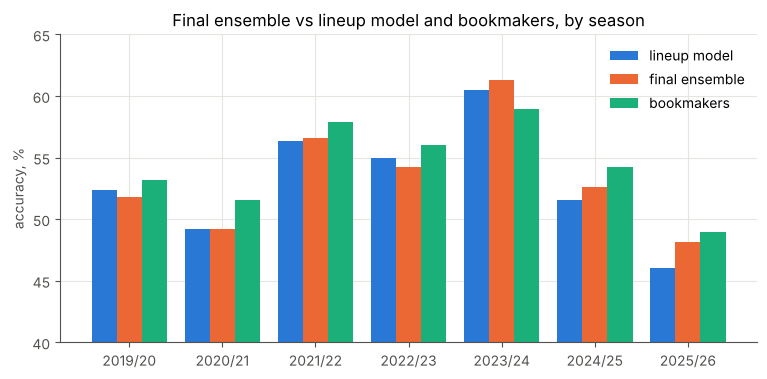

,season,matches,lineup_model,ensemble,bookmakers,ensemble_rps,bookmakers_rps
0,2019/20,380,52.4,51.8,53.2,0.2009,0.1987
1,2020/21,380,49.2,49.2,51.6,0.2204,0.2131
2,2021/22,380,56.3,56.6,57.9,0.1923,0.1890
3,2022/23,380,55.0,54.2,56.0,0.2017,0.1991
4,2023/24,380,60.5,61.3,59.0,0.1832,0.1838
5,2024/25,380,51.6,52.6,54.2,0.1999,0.1974
6,2025/26,380,46.1,48.2,48.9,0.2105,0.2057


In [21]:
fb = pd.read_csv(ROOT / "reports/final_backtest_by_season.csv")
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(fb))
for i, (c, lab, col) in enumerate([("lineup_model", "lineup model", "#2a78d6"), ("ensemble", "final ensemble", "#eb6834"), ("bookmakers", "bookmakers", "#1baf7a")]):
    ax.bar(x + (i - 1) * 0.27, 100 * fb[c], 0.27, label=lab, color=col)
ax.set_xticks(x, fb.season); ax.set_ylim(40, 65); ax.set_ylabel("accuracy, %"); ax.legend(frameon=False)
ax.set_title("Final ensemble vs lineup model and bookmakers, by season")
plt.show()
fb.assign(**{c: (100 * fb[c]).round(1) for c in ["lineup_model", "ensemble", "bookmakers"]})

## 8. Everything else that was tried

`src/experiments.py` tested 48 combinations on the same 7-season backtest:
- **Extra training data:** the Championship and the other top-5 leagues, up to 59,800 matches.
- **ClubElo ratings:** these compare clubs across leagues through European games, which helps rate promoted teams.
- **Pi-ratings:** separate home and away strength for each team.
- **Shots-on-target ratings:** a rough substitute for expected goals.
- **Models:** logistic regression, gradient boosting, and the average of the two.

**RPS** (ranked probability score) measures the quality of the *probabilities*, not just the pick. It treats predicting an away win when the home team won as worse than predicting a draw. Lower is better.

In [22]:
exp = pd.read_csv(ROOT / "reports/experiments.csv")
print("Best 8 configurations by RPS, plus the bookmaker reference:")
exp.head(9).assign(accuracy=lambda d: (d.accuracy * 100).round(1))

Best 8 configurations by RPS, plus the bookmaker reference:


,features,pool,model,accuracy,rps
0,bookmakers,-,-,54.4,0.1981
1,base+clubelo+pi+shots,PL+Championship,ensemble,52.9,0.2024
2,base+clubelo+pi+shots,top-5 leagues,gbm,52.7,0.2025
3,base+clubelo+pi+shots,top-5 leagues,ensemble,52.7,0.2026
4,base+clubelo+pi+shots,PL+Championship,gbm,52.9,0.2026
5,base+clubelo+pi+shots,PL+Championship,logreg,52.3,0.2028
6,base+clubelo+pi+shots,top-5 + Championship,ensemble,52.6,0.2028
7,base+clubelo+pi+shots,top-5 + Championship,logreg,52.3,0.2029
8,base+clubelo+pi+shots,PL only,ensemble,52.7,0.2029


In [23]:
models = exp[exp.features != "bookmakers"]
print(f"Accuracy range across all {len(models)} configurations: {models.accuracy.min():.1%} to {models.accuracy.max():.1%}")

Accuracy range across all 48 configurations: 51.9% to 52.9%


Every configuration lands within about one standard error (±1 point) of the others. More data and fancier ratings make the probabilities *slightly* sharper, but they don't change which result gets picked, so accuracy doesn't move. The data simply has no more signal in it.

## 9. When to trust the model

Accuracy over all matches hides something useful. The model knows when it's unsure. Grouping the 2,660 backtest predictions by how confident the model was (`src/evaluate_v2.py`):

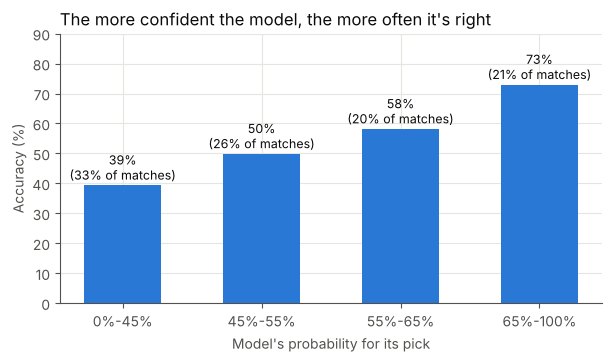

,confidence,matches,share,accuracy
0,0%-45%,866,0.326,0.394
1,45%-55%,704,0.265,0.499
2,55%-65%,541,0.203,0.582
3,65%-100%,549,0.206,0.730


In [24]:
conf = pd.read_csv(ROOT / "reports/v2_accuracy_by_confidence.csv")
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(conf.confidence, conf.accuracy * 100, color=BLUE, width=0.55)
for b, (acc, share) in zip(bars, zip(conf.accuracy, conf.share)):
    ax.annotate(f"{acc:.0%}\n({share:.0%} of matches)", (b.get_x() + b.get_width() / 2, b.get_height()),
                xytext=(0, 4), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_ylim(0, 90)
ax.set_xlabel("Model's probability for its pick")
ax.set_ylabel("Accuracy (%)")
ax.set_title("The more confident the model, the more often it's right", loc="left", color=INK)
plt.show()
conf

When the model gives its pick at least a 65% chance (about 1 match in 5), it's right about **73%** of the time. When it's below 45%, it's barely better than guessing. For a demo, *"here's the pick, and here's how much to trust it"* is far more useful than one accuracy number.

## 10. This season and this weekend

The 2026/27 season so far: 50 matches, never seen during training or model selection.

In [25]:
t = pd.read_csv(ROOT / "reports/test_2026_27_predictions.csv")
print(f"Correct: {t.Correct.sum()} of {len(t)} ({t.Correct.mean():.0%}).  Home wins so far this season: {(t.Result == 'H').mean():.0%} (usual: ~45%)")
t[["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "pH", "pD", "pA", "Pick", "Correct"]].tail(10)

Correct: 23 of 50 (46%).  Home wins so far this season: 36% (usual: ~45%)


,Date,HomeTeam,AwayTeam,FTHG,FTAG,pH,pD,pA,Pick,Correct
40,2026-09-18,Brentford,Chelsea,3.0,0.0,0.448,0.268,0.284,H,True
41,2026-09-19,Brighton,Arsenal,3.0,0.0,0.282,0.233,0.485,A,False
42,2026-09-19,Everton,Ipswich,1.0,0.0,0.665,0.201,0.133,H,True
43,2026-09-19,Newcastle,Hull,2.0,1.0,0.589,0.241,0.171,H,True
44,2026-09-19,Nott'm Forest,Coventry,0.0,1.0,0.676,0.200,0.124,H,False
45,2026-09-19,Tottenham,Aston Villa,2.0,3.0,0.310,0.262,0.428,A,True
46,2026-09-20,Bournemouth,Liverpool,0.0,1.0,0.381,0.272,0.346,H,False
47,2026-09-20,Fulham,Man United,1.0,1.0,0.305,0.279,0.416,A,False
48,2026-09-20,Leeds,Crystal Palace,0.0,0.0,0.499,0.263,0.238,H,False
49,2026-09-20,Man City,Sunderland,5.0,3.0,0.763,0.162,0.074,H,True


50 matches is too few to judge a model; accuracy over 50 matches easily swings ±7 points. This season has also started with unusually few home wins, which hurts every model that knows about home advantage. The 7-season backtest is the number to trust.

**Next matchday** (`src/predict_next.py`, trained on every match played so far):

In [26]:
pd.read_csv(ROOT / "reports/next_matchday_predictions.csv")

,Date,HomeTeam,AwayTeam,HomeElo,AwayElo,pH,pD,pA,Pick
0,2026-10-10,Arsenal,Leeds,1749.0,1551.0,0.692,0.199,0.109,H
1,2026-10-10,Aston Villa,Brentford,1575.0,1590.0,0.426,0.278,0.296,H
2,2026-10-10,Chelsea,Bournemouth,1556.0,1586.0,0.385,0.277,0.338,H
3,2026-10-10,Ipswich,Fulham,1441.0,1518.0,0.298,0.298,0.405,A
4,2026-10-10,Man United,Tottenham,1618.0,1453.0,0.612,0.240,0.148,H
5,2026-10-10,Sunderland,Brighton,1505.0,1615.0,0.270,0.292,0.438,A
6,2026-10-11,Crystal Palace,Nott'm Forest,1502.0,1541.0,0.383,0.289,0.328,H
7,2026-10-11,Hull,Everton,1471.0,1552.0,0.283,0.290,0.427,A
8,2026-10-11,Liverpool,Man City,1644.0,1759.0,0.324,0.252,0.425,A
9,2026-10-12,Coventry,Newcastle,1424.0,1560.0,0.258,0.291,0.450,A


## 11. Conclusions

1. **Honest accuracy is about 53%**: 52.7% from results only, 53.4% for the final model (results + lineups, ensemble of five), against 43% for always picking home and 54% for the bookmakers. The 82% in 2023 came from leakage.
2. **Each team's recent results are the core of the model**, through Elo and form.
3. **Head-to-head history and weather were tested properly and don't help.** Elo already covers head-to-head, and weather affects goals, not winners.
4. **More data and more complex models didn't help either.** Longer form, other ratings, tuning, recency weighting, other model families, recalibration and five-league training all failed a development/confirmation split. Only averaging five model variants held up, and it is a small gain (RPS 0.2022 → 0.2013). The limit is the information, not the algorithm.
5. **Of everything tested, only team news (lineups) clearly helped, with xG as a promising second.** Congestion, stakes, manager changes, player ratings and suspensions added nothing beyond what the model already knew.
6. **Team news, in more detail:** Confirmed lineups (who is missing compared with usual) made the probabilities clearly better, though accuracy barely moved. Using them live needs the lineups collected about an hour before kickoff, for example with an Apify scraper. The bookmakers are still slightly ahead because they know the same news earlier, and more of it.
7. **Report confidence, not just a pick.** At 65%+ confidence (22% of matches) the final model is right 73% of the time; at 70%+ (15% of matches), 75%.